# Downloading Data

In [1]:
!kaggle datasets download blourdhuraju/dogs-vs-cats-classification

Dataset URL: https://www.kaggle.com/datasets/blourdhuraju/dogs-vs-cats-classification
License(s): CC0-1.0
100% 775M/775M [00:09<00:00, 86.0MB/s]



In [2]:
!unzip /content/dogs-vs-cats-classification.zip

Streaming output truncated to the last 5000 lines.
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07458.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07459.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07460.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07461.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07462.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07463.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07464.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07465.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07466.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07467.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07468.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train_07469.jpg  
  inflating: dogs-vs-cats-classification/train/dogs/dog_train

# Importing libs

In [14]:
import os
import random
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2 as cv
import pandas as pd
import numpy as np

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Loading csv info

In [ ]:
csv_info = pd.read_csv('/content/dogs-vs-cats-classification/dataset_info.csv')
csv_info

,filename,split,class,label,source
0,cat_train_00000.jpg,train,cats,0,5459.jpg
1,cat_train_00001.jpg,train,cats,0,1170.jpg
2,cat_train_00002.jpg,train,cats,0,8855.jpg
3,cat_train_00003.jpg,train,cats,0,826.jpg
4,cat_train_00004.jpg,train,cats,0,5104.jpg
...,...,...,...,...,...
24925,dog_test_01242.jpg,test,dogs,1,11613.jpg
24926,dog_test_01243.jpg,test,dogs,1,5622.jpg
24927,dog_test_01244.jpg,test,dogs,1,6661.jpg
24928,dog_test_01245.jpg,test,dogs,1,8252.jpg


# EDA

In [5]:
train_path = '/content/dogs-vs-cats-classification/train'
val_path = '/content/dogs-vs-cats-classification/validation'
test_path = '/content/dogs-vs-cats-classification/test'

classes = ["cats", "dogs"]
dataFrame = {
    "classes":classes
}

for sub in ["train","validation","test"]:
  folder_path = os.path.join("/content/dogs-vs-cats-classification",sub)
  dataFrame[sub]=[
      len(os.listdir(os.path.join(folder_path,classes[0]))),
      len(os.listdir(os.path.join(folder_path,classes[1])))
  ]

balance= pd.DataFrame(dataFrame)
balance

,classes,train,validation,test
0,cats,9977,1247,1248
1,dogs,9966,1245,1247


## Checking the balance

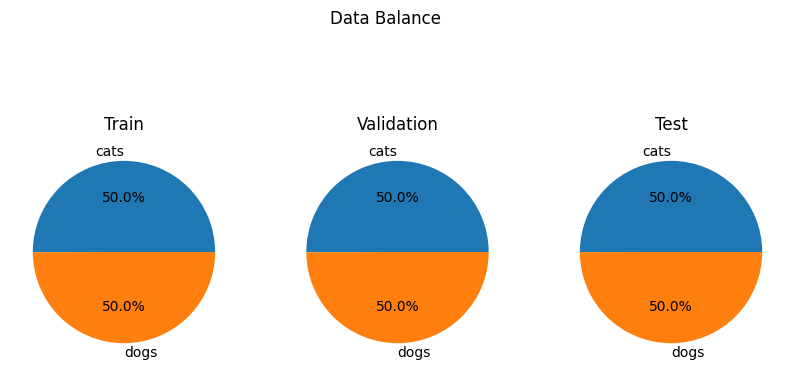

In [ ]:
fig,axes = plt.subplots(1,3,figsize=(10,5))

axes[0].pie(balance["train"],labels=balance["classes"],autopct='%1.1f%%')
axes[0].set_title("Train")

axes[1].pie(balance["validation"],labels=balance["classes"],autopct='%1.1f%%')
axes[1].set_title("Validation")

axes[2].pie(balance["test"],labels=balance["classes"],autopct='%1.1f%%')
axes[2].set_title("Test")

fig.suptitle("Data Balance")
plt.show()

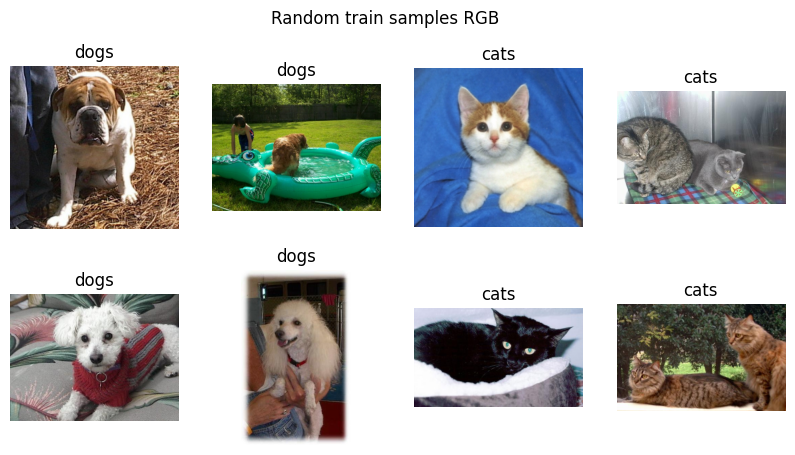

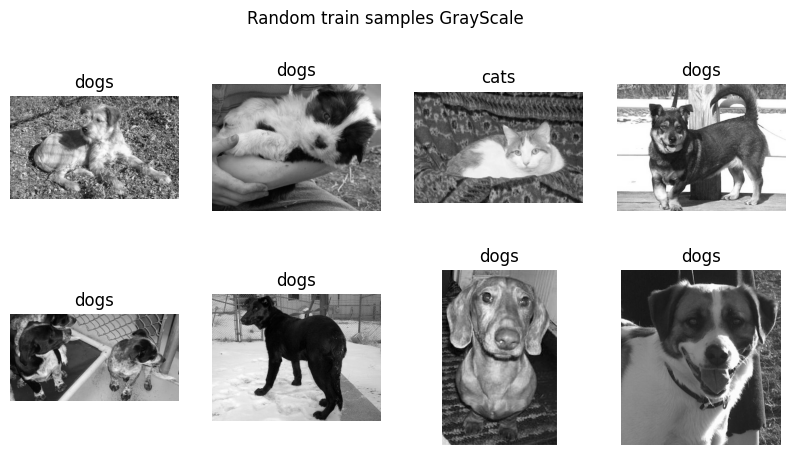

In [ ]:
fig,axes = plt.subplots(2,4,figsize=(10,5))

for ax in axes.flatten():
  random_cls = random.choice(classes)
  random_img = random.choice(os.listdir(os.path.join(train_path,random_cls)))
  img = Image.open(os.path.join(train_path,random_cls,random_img))
  ax.imshow(img)
  ax.axis("off")
  ax.set_title(random_cls)
fig.suptitle("Random train samples RGB")
plt.show()

fig,axes = plt.subplots(2,4,figsize=(10,5))

for ax in axes.flatten():
  random_cls = random.choice(classes)
  random_img = random.choice(os.listdir(os.path.join(train_path,random_cls)))
  img = Image.open(os.path.join(train_path,random_cls,random_img)).convert('L')
  ax.imshow(img,cmap="gray")
  ax.axis("off")
  ax.set_title(random_cls)
fig.suptitle("Random train samples GrayScale")
plt.show()

## Finding best dimention for all images

```python
import cv2 as cv
```

Image dims(Height,Width) : (288, 291)


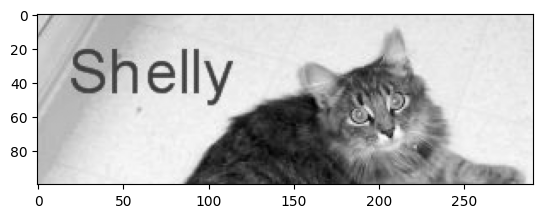

In [6]:
img= cv.imread("/content/dogs-vs-cats-classification/train/cats/cat_train_00000.jpg")

img = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

print("Image dims(Height,Width) :",img.shape)

plt.imshow(img[:100],cmap="gray")
# plt.axis("off")
plt.show()

In [ ]:
width = np.array([])
height = np.array([])



for img_name in os.listdir(os.path.join(train_path,"cats")):
  img_path = os.path.join(train_path,"cats",img_name)
  img = cv.imread(img_path)
  if img is not None:
    height = np.append(height, img.shape[0])
    width = np.append(width, img.shape[1])

for img_name in os.listdir(os.path.join(train_path,"dogs")):
  img_path = os.path.join(train_path,"dogs",img_name)
  img = cv.imread(img_path)
  if img is not None:
    height = np.append(height, img.shape[0])
    width = np.append(width, img.shape[1])

print("Mean of Height:",np.mean(height))
print("Median of Height:",np.median(height))
print("Mean of Width:",np.mean(width))
print("Median of Width:",np.median(width))

Mean of Height: 361.828210399639
Median of Height: 375.0
Mean of Width: 405.34994734994734
Median of Width: 448.0


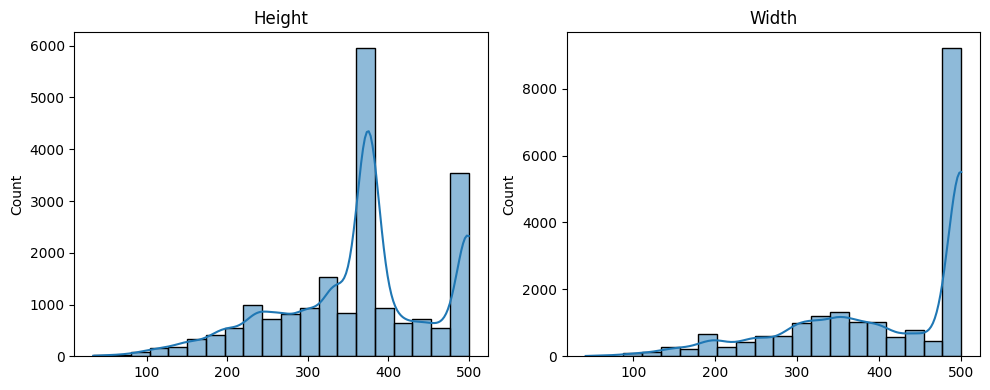

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(121)
sns.histplot(height,bins=20,kde=True)
plt.title("Height")
plt.subplot(122)
sns.histplot(width,bins=20,kde=True)
plt.title("Width")
plt.tight_layout()
plt.show()

- I will standardize the median values. (375,448)

# Data Augmentation &Preprocessing

```python
import albumentations as A
from albumentations.pytorch import ToTensorV2
```

In [7]:
train_transforms = A.Compose([

    A.HorizontalFlip(p=0.2),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.2),

    A.Resize(height=375, width=448),

    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.CLAHE(p=0.5),

    A.ToFloat(max_value=255.0),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(height=375, width=448),
    A.ToFloat(max_value=255.0),
    ToTensorV2(),
])

# Dataset Class

>for Creating object carries (images_paths, labels, transform for preprocessing), and can iterating from it

```python
import torch
from torch.utils.data import Dataset, DataLoader
```

In [8]:
class CatsDogsDataset(Dataset):
  def __init__(self, root_dir: str, transform = None):
    self.transform = transform
    self.image_paths = []
    self.labels = []

    self.classes = os.listdir(root_dir)
    self.classes_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

    for cls in self.classes:
      cls_dir = os.path.join(root_dir,cls)
      for image_name in os.listdir(cls_dir):
        self.image_paths.append(os.path.join(cls_dir,image_name))
        self.labels.append(self.classes_to_idx[cls])

  def __len__(self):
    return len(self.image_paths)

  def __getitem__(self, idx):
    image = cv.imread(self.image_paths[idx])
    image = cv.cvtColor(image,cv.COLOR_BGR2GRAY)
    label = self.labels[idx]

    if self.transform:
      augmentd = self.transform(image=image)
      image = augmentd["image"]

    return image, torch.tensor(label)

# Data Loader

In [9]:
train_dataset = CatsDogsDataset(train_path,train_transforms)
train_loader = DataLoader(train_dataset,batch_size=16,shuffle=True)

val_dataset = CatsDogsDataset(val_path,val_transforms)
val_loader = DataLoader(val_dataset,batch_size=16,shuffle=False)

In [ ]:
train_dataset.classes_to_idx

{'dogs': 0, 'cats': 1}

In [ ]:
images, labels = next(iter(train_loader))

print("Batch Images Shape:", images.shape)
print("Batch Labels Shape:", labels.shape)

Batch Images Shape: torch.Size([16, 1, 375, 448])
Batch Labels Shape: torch.Size([16])


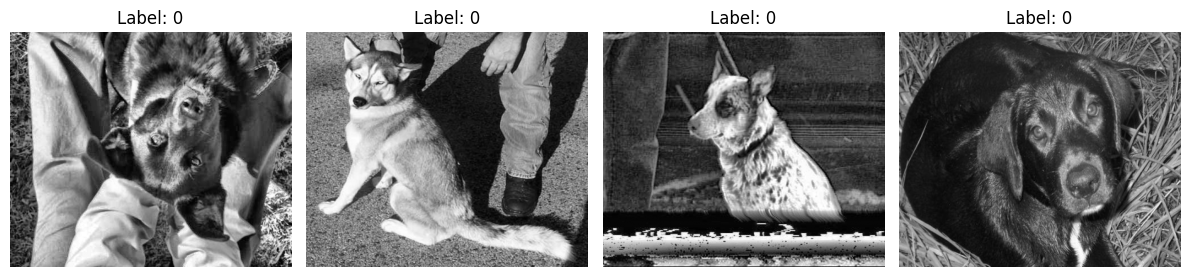

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    img = images[i].squeeze(0).numpy()
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

# Building Model

```python
import torch.nn as nn
```

![](https://i0.wp.com/syncedreview.com/wp-content/uploads/2017/05/13.png?resize=330%2C230&ssl=1)

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRPYcLrRxbHKjU4JzUE1AEhSZPB8YF-StPCtfpzEqEmPQ&s=10)

In [ ]:
# To calc dimensions

dummy_img = torch.randn(1,1,375,448)

nn.MaxPool2d(2,2)(
    nn.BatchNorm2d(32)(
      nn.Conv2d(in_channels=1,out_channels=32,kernel_size=5,stride=1,padding=2)(dummy_img)
      )
    ).shape

torch.Size([1, 32, 187, 224])

In [10]:
class PyTorchModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 5, padding=2)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.flatten = nn.Flatten()

        self.linear1 = nn.Linear(256, 128)
        self.bnfc1 = nn.BatchNorm1d(128)

        self.linear2 = nn.Linear(128, 64)
        self.bnfc2 = nn.BatchNorm1d(64)

        self.linear3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):

        x = self.pool(
            self.relu(
                self.bn1(self.conv1(x))
            )
        )

        x = self.pool(
            self.relu(
                self.bn2(self.conv2(x))
            )
        )

        x = self.pool(
            self.relu(
                self.bn3(self.conv3(x))
            )
        )

        x = self.pool(
            self.relu(
                self.bn4(self.conv4(x))
            )
        )

        x = self.global_pool(x)

        x = self.flatten(x)

        x = self.relu(self.bnfc1(self.linear1(x)))

        x = self.relu(self.bnfc2(self.linear2(x)))

        x = self.dropout(x)

        x = self.linear3(x)

        return x



dummy_model = PyTorchModel().to(device)
dummy_model.eval()
print(
    "Output Shape:",
    dummy_model(torch.randn(1,1,375,448).to(device)).shape
)

print("All good ✨")

Output Shape: torch.Size([1, 1])
All good ✨


In [11]:
del dummy_model
torch.cuda.empty_cache()

## Initialize He/Kaiming normal

In [ ]:
def init_weights(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)

# model.apply(init_weights)

## Training loop

In [ ]:

def fit(model, epochs, optimizer, scheduler, criterion, train_loader, val_loader, device, file_name):

  best_f1=0
  counter =0
  ES_patience = 10
  for epoch in range(epochs):
    torch.cuda.empty_cache()
    model.train()
    train_loss = 0.0
    train_f1 = 0.0


    # LEARNING SECTION
    for x_batch, y_batch in train_loader:
      images = x_batch.to(device)
      labels = y_batch.to(device).float().unsqueeze(1)

      optimizer.zero_grad()
      outputs = model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()

      train_loss += loss.item() * len(images) #total loss after each batch
      train_preds = torch.round(torch.sigmoid(outputs))
      # Fix: Detach tensors before converting to CPU for f1_score
      train_f1 += f1_score(labels.detach().cpu(), train_preds.detach().cpu(), average='binary')
    train_loss /= len(train_loader.dataset) # AVG loss at all images data set
    train_f1 /= len(train_loader)

    #EVAL SECTION
    model.eval()
    all_preds =[] #Becuase of we are passing eval images by batches
    all_labels =[]
    with torch.no_grad():
      for x_batch,y_batch in val_loader:
        images = x_batch.to(device)


        outputs = model(images)
        val_preds = torch.round(torch.sigmoid(outputs))
        all_preds.extend(val_preds.cpu())
        all_labels.extend(y_batch)
    val_f1 = f1_score(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu(), average='binary')
    scheduler.step(val_f1)

    if val_f1 > best_f1:
      best_f1 = val_f1
      counter = 0
      torch.save(model.state_dict(), file_name+".pth")
    else:
      counter += 1
      if counter >= ES_patience:
        print("Early stopping")
        break
    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}")


## Modeling with SGD+Momentum

In [ ]:
MSGD_model = PyTorchModel().to(device)
MSGD_model.apply(init_weights)

optimizer = torch.optim.SGD(MSGD_model.parameters(), lr=0.01, momentum=0.9)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

criterion = nn.BCEWithLogitsLoss()

fit(MSGD_model, 100, optimizer, scheduler, criterion, train_loader, val_loader, device, "MSGD_model")

Epoch 1/100 | Train Loss: 0.8027 | Train F1: 0.4748 | Val F1: 0.6171
Epoch 2/100 | Train Loss: 0.6908 | Train F1: 0.5003 | Val F1: 0.6715
Epoch 3/100 | Train Loss: 0.6818 | Train F1: 0.5691 | Val F1: 0.6746
Epoch 4/100 | Train Loss: 0.6758 | Train F1: 0.5866 | Val F1: 0.5856
Epoch 5/100 | Train Loss: 0.6678 | Train F1: 0.6037 | Val F1: 0.6671
Epoch 6/100 | Train Loss: 0.6589 | Train F1: 0.6249 | Val F1: 0.7062
Epoch 7/100 | Train Loss: 0.6472 | Train F1: 0.6292 | Val F1: 0.7025
Epoch 8/100 | Train Loss: 0.6267 | Train F1: 0.6566 | Val F1: 0.6974
Epoch 9/100 | Train Loss: 0.6160 | Train F1: 0.6670 | Val F1: 0.7445
Epoch 10/100 | Train Loss: 0.6034 | Train F1: 0.6778 | Val F1: 0.7227
Epoch 11/100 | Train Loss: 0.5931 | Train F1: 0.6848 | Val F1: 0.7236
Epoch 12/100 | Train Loss: 0.5858 | Train F1: 0.6918 | Val F1: 0.4320
Epoch 13/100 | Train Loss: 0.5760 | Train F1: 0.7020 | Val F1: 0.6722
Epoch 14/100 | Train Loss: 0.5556 | Train F1: 0.7159 | Val F1: 0.7267
Epoch 15/100 | Train Loss: 0.

KeyboardInterrupt: 

In [ ]:
best_MSGD_model = PyTorchModel().to(device)
best_MSGD_model.load_state_dict(torch.load("MSGD_model.pth"))

<All keys matched successfully>

In [ ]:
train_eval_dataset = CatsDogsDataset(train_path,val_transforms)
train_eval_loader = DataLoader(train_eval_dataset,batch_size=16,shuffle=False)

test_data = CatsDogsDataset(test_path,val_transforms)
test_loader = DataLoader(test_data,batch_size=16,shuffle=False)

best_MSGD_model.eval()
all_preds =[] #Becuase of we are passing eval images by batches
all_labels =[]
with torch.no_grad():
  for x_batch,y_batch in train_eval_loader:
    images = x_batch.to(device)


    outputs = best_MSGD_model(images)
    val_preds = torch.round(torch.sigmoid(outputs))
    all_preds.extend(val_preds.cpu())
    all_labels.extend(y_batch)
train_f1 = f1_score(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu(), average='binary')
print("train F1 in Evaluation mode:",train_f1)
with torch.no_grad():
  all_preds =[] #Becuase of we are passing eval images by batches
  all_labels =[]
  for x_batch,y_batch in test_loader:
    images = x_batch.to(device)


    outputs = best_MSGD_model(images)
    val_preds = torch.round(torch.sigmoid(outputs))
    all_preds.extend(val_preds.cpu())
    all_labels.extend(y_batch)
val_f1 = f1_score(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu(), average='binary')
print("test F1 score:", val_f1)


train F1 in Evaluation mode: 0.8883140142281478
test F1 score: 0.8721804511278195


## Modeling With ADAM

In [ ]:
ADAM_model = PyTorchModel().to(device)
ADAM_model.apply(init_weights)

optimizer = torch.optim.Adam(ADAM_model.parameters(), lr=0.001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

criterion = nn.BCEWithLogitsLoss()

fit(ADAM_model, 100, optimizer, scheduler, criterion, train_loader, val_loader, device, "ADAM_model")

Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 1/100 | Train Loss: 1.4125 | Train F1: 0.5131 | Val F1: 0.4778


Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 2/100 | Train Loss: 0.9291 | Train F1: 0.5132 | Val F1: 0.6580


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


...

Epoch 51/100 | Train Loss: 0.2144 | Train F1: 0.9108 | Val F1: 0.9037


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 52/100 | Train Loss: 0.2020 | Train F1: 0.9147 | Val F1: 0.9257


Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Early stopping


In [12]:
best_ADAM_model = PyTorchModel().to(device)
best_ADAM_model.load_state_dict(torch.load("/content/ADAM_model.pth"))

<All keys matched successfully>

In [13]:
train_eval_dataset = CatsDogsDataset(train_path,val_transforms)
train_eval_loader = DataLoader(train_eval_dataset,batch_size=16,shuffle=False)

test_data = CatsDogsDataset(test_path,val_transforms)
test_loader = DataLoader(test_data,batch_size=16,shuffle=False)

best_ADAM_model.eval()
all_preds =[] #Becuase of we are passing eval images by batches
all_labels =[]
with torch.no_grad():
  for x_batch,y_batch in train_eval_loader:
    images = x_batch.to(device)


    outputs = best_ADAM_model(images)
    val_preds = torch.round(torch.sigmoid(outputs))
    all_preds.extend(val_preds.cpu())
    all_labels.extend(y_batch)
train_f1 = f1_score(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu(), average='binary')
print("train F1 in Evaluation mode:",train_f1)
all_preds =[] #Becuase of we are passing eval images by batches
all_labels =[]
with torch.no_grad():
  for x_batch,y_batch in test_loader:
    images = x_batch.to(device)


    outputs = best_ADAM_model(images)
    val_preds = torch.round(torch.sigmoid(outputs))
    all_preds.extend(val_preds.cpu())
    all_labels.extend(y_batch)
val_f1 = f1_score(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu(), average='binary')
print("test F1 score:", val_f1)


train F1 in Evaluation mode: 0.9534813624032955
test F1 score: 0.9156237383932176


- I'll choose Adam model with 92% F1 score

# Evaluating Model

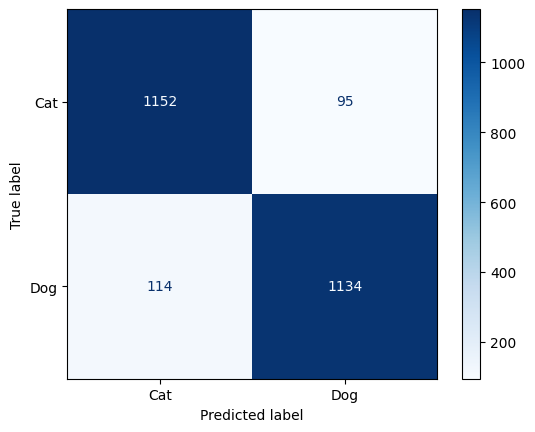

In [16]:
ConfusionMatrixDisplay(confusion_matrix(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu()),display_labels=["Cat","Dog"]).plot(cmap="Blues")

In [22]:
print(classification_report(torch.tensor(all_labels).detach().cpu(), torch.tensor(all_preds).detach().cpu(),target_names=["Cat","Dog"]))

              precision    recall  f1-score   support

         Cat       0.91      0.92      0.92      1247
         Dog       0.92      0.91      0.92      1248

    accuracy                           0.92      2495
   macro avg       0.92      0.92      0.92      2495
weighted avg       0.92      0.92      0.92      2495



Found 209 incorrect predictions.


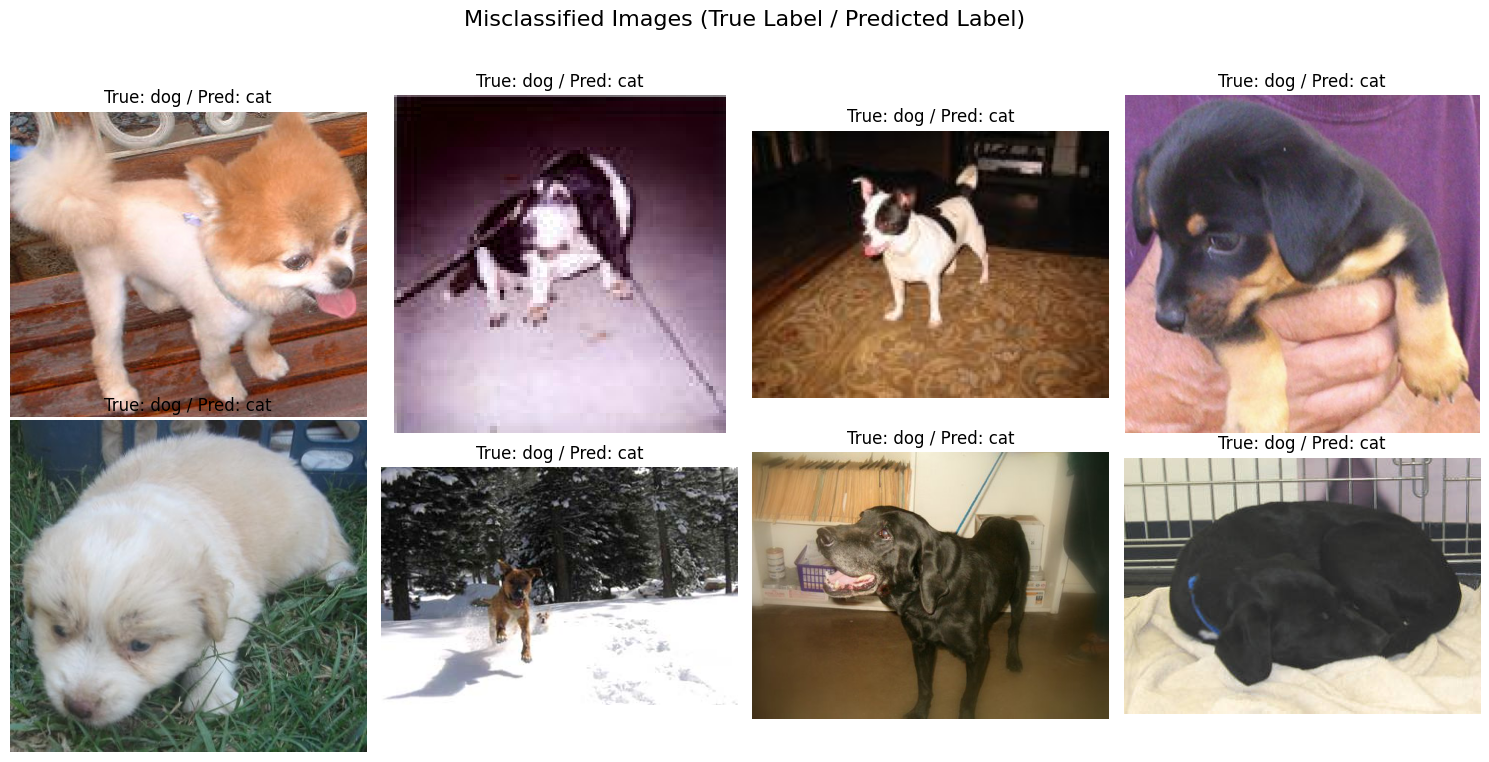

In [17]:
import matplotlib.pyplot as plt

incorrect_predictions_indices = []
for i in range(len(all_labels)):
    if all_labels[i].item() != int(all_preds[i].item()):
        incorrect_predictions_indices.append(i)

print(f"Found {len(incorrect_predictions_indices)} incorrect predictions.")

# Display a few of the misclassified images
num_images_to_display = min(8, len(incorrect_predictions_indices))

if num_images_to_display > 0:
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    fig.suptitle("Misclassified Images (True Label / Predicted Label)", fontsize=16)

    for i, ax in enumerate(axes.flatten()):
        if i < num_images_to_display:
            idx = incorrect_predictions_indices[i]
            image_path = test_data.image_paths[idx]
            true_label = 'dog' if all_labels[idx].item() == 0 else 'cat'
            predicted_label = 'dog' if int(all_preds[idx].item()) == 0 else 'cat'

            img = Image.open(image_path).convert('RGB') # Load as RGB for display
            ax.imshow(img)
            ax.set_title(f"True: {true_label} / Pred: {predicted_label}")
            ax.axis('off')
        else:
            ax.axis('off') # Turn off empty subplots
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
else:
    print("No incorrect predictions to display.")